In [1]:
!pip install pygam

In [2]:
##################### Filtering variables #######################################################################

In [3]:
# Checking possible predictors using correlation

import numpy as np,pandas as pd,matplotlib.pyplot as plt
from pathlib import Path

# Loading dataset
Mypath=Path.home()/"Desktop"/"NBA_Project"/"data"/"processed"/"nba_final_player_season_data.csv"
NBA_df=pd.read_csv(Mypath)

print(f"Original rows: {NBA_df.shape[0]:,}   Columns: {NBA_df.shape[1]}")

# Cleaning data
NBA_df=NBA_df.replace([np.inf,-np.inf],np.nan)
NBA_df=NBA_df[NBA_df["games_played"]>0].copy()

# Creating per game variables
base_components=[
    "points","rebounds","assists",
    "steals","blocks","turnovers"
]

volume_vars=base_components+[
    "plus_minus","offensive_rebounds","defensive_rebounds",
    "blocks_against","personal_fouls","personal_fouls_drawn",
    "two_point_points","three_point_points",
    "two_point_attempts","three_point_attempts","free_throw_attempts",
    "field_goal_attempts","field_goals_made",
    "two_points_made","three_points_made","free_throws_made"
]

volume_vars=[c for c in volume_vars if c in NBA_df.columns]

for c in volume_vars:
    NBA_df[f"{c}_per_game"]=NBA_df[c]/NBA_df["games_played"]

NBA_df["nba_fantasy_points_per_game"]=NBA_df["nba_fantasy_points"]/NBA_df["games_played"]

# Removing players with few games
min_games=20
NBA_df=NBA_df[NBA_df["games_played"]>=min_games].copy()

print(f"Rows after minimum-games filter: {NBA_df.shape[0]:,}")
print(f"Minimum games played: {min_games}")

target="nba_fantasy_points_per_game"

# Defining fantasy point components
components=[
    "points_per_game","rebounds_per_game","assists_per_game",
    "steals_per_game","blocks_per_game","turnovers_per_game"
]

# Excluding variables not needed for the analysis
exclude_vars=base_components+components+[target,"nba_fantasy_points"]+volume_vars+[
    "games_played","minutes","player_id",
    "team_id","year","wins",
    "losses","team_wins","team_losses",
    "true_shooting_pct","field_goal_pct",
    # Excluding wins and losses because win_pct already shows winning performance
    # without also depending on the number of games played.
    # Excluding true_shooting_pct because the separate shooting percentages give more detail.
    # Excluding field_goal_pct because two-point and three-point percentages are more specific.
    "career_start_year","career_end_year",
    "draft_year","roster_status",
    "actual_playoff_team"
]

# Selecting numerical predictors
candidate_predictors=[
    c for c in NBA_df.select_dtypes("number")
    if c not in exclude_vars and NBA_df[c].std()>0
]

# Calculating correlations
corr=pd.DataFrame({
    "with_target":NBA_df[candidate_predictors].corrwith(NBA_df[target]).abs(),
    "with_component":NBA_df[candidate_predictors].apply(
        lambda s:NBA_df[components].corrwith(s).abs().max()
    )
}).round(3)

corr["criterion"]=corr.max(axis=1)
corr=corr.sort_values("criterion",ascending=False)

display(corr)
print(f"\nCandidate predictors after initial exclusion: {len(candidate_predictors)}")

Original rows: 14,569   Columns: 67
Rows after minimum-games filter: 12,073
Minimum games played: 20


,with_target,with_component,criterion
field_goals_made_per_game,0.947,0.989,0.989
field_goal_attempts_per_game,0.919,0.982,0.982
defensive_rebounds_per_game,0.800,0.974,0.974
two_points_made_per_game,0.903,0.896,0.903
free_throws_made_per_game,0.846,0.893,0.893
two_point_attempts_per_game,0.885,0.890,0.890
offensive_rebounds_per_game,0.476,0.875,0.875
assist_pct,0.401,0.874,0.874
free_throw_attempts_per_game,0.852,0.872,0.872
double_doubles,0.704,0.791,0.791



Candidate predictors after initial exclusion: 34


In [4]:
# Removing predictors that are too close to the target or its components.

# Those variables computed from the components of the target. They are rescaled
# versions of the outcome and are removed regardless of their correlation.
by_definition = [
    "triple_doubles",           # 10+ in three of PTS / REB / AST
    "double_doubles",           # 10+ in two of PTS / REB / AST
    "usage_pct",                # from shot attempts, free throws, turnovers
    "assist_pct",               # from assists
    "offensive_rebound_pct",    # from rebounds
    "defensive_rebound_pct",    # from rebounds
]

survivors = [c for c in corr.index[corr.criterion <= 0.60] if c not in by_definition]
display(corr.loc[survivors])

,with_target,with_component,criterion
three_point_attempts_per_game,0.441,0.573,0.573
three_points_made_per_game,0.429,0.565,0.565
height_cm,0.027,0.541,0.541
weight_kg,0.049,0.486,0.486
free_throw_pct,0.242,0.351,0.351
two_point_pct,0.243,0.348,0.348
net_rating,0.330,0.285,0.330
plus_minus_per_game,0.310,0.274,0.310
three_point_pct,0.141,0.289,0.289
player_experience_years,0.169,0.166,0.169


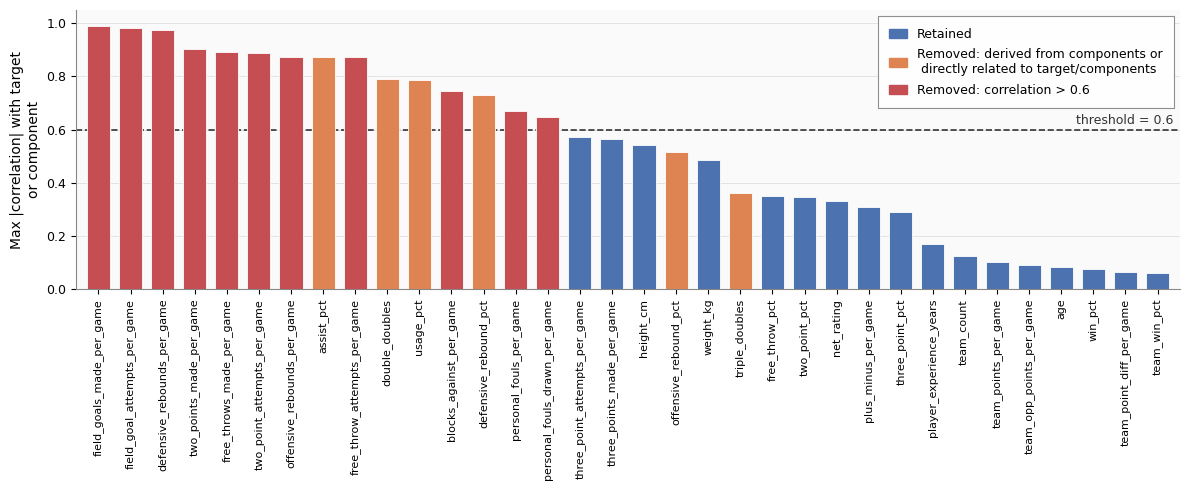

In [5]:
from matplotlib.patches import Patch

TH = 0.60  # threshold

p = corr.sort_values("criterion", ascending=False)
col = ["#dd8452" if n in by_definition else ("#c44e52" if v > TH else "#4c72b0")
       for n, v in p["criterion"].items()]

fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor("white")
ax.set_facecolor("#fafafa")

bars = ax.bar(
    p.index, p["criterion"],
    color=col, edgecolor="white", linewidth=0.6, width=0.72, zorder=3
)

ax.axhline(TH, color="#333333", ls="--", lw=1.2, zorder=2)
ax.text(len(p) - 0.5, TH + 0.02, f"threshold = {TH}",
        ha="right", fontsize=9, color="#333333")

ax.set_ylabel("Max |correlation| with target\nor component", fontsize=10)
ax.set_ylim(0, 1.05)

plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8)
ax.tick_params(axis="y", labelsize=9)
ax.set_xlim(-0.7, len(p) - 0.3)

ax.grid(axis="y", color="#d9d9d9", linestyle="-", linewidth=0.7, alpha=0.7, zorder=0)
ax.set_axisbelow(True)

for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")

# Legend boxed and placed inside the plot, upper-right
legend = ax.legend(
    handles=[
        Patch(color="#4c72b0", label="Retained"),
        Patch(color="#dd8452", label="Removed: derived from components or\n directly related to target/components"),
        Patch(color="#c44e52", label="Removed: correlation > 0.6"),
    ],
    fontsize=9, loc="upper right",
    frameon=True, fancybox=False, edgecolor="#888888",
    facecolor="white", framealpha=0.95,
    borderpad=0.9, labelspacing=0.6, handlelength=1.4,
)
legend.get_frame().set_linewidth(0.8)

fig.tight_layout()
fig.savefig("predictor_screening.pdf", dpi=300, bbox_inches="tight")
plt.show()

toPath= (Path.home()/ "Desktop"/ "NBA_Project"/ "code"/ "analysis" / "Regression")
# Append the actual filename to the folder path
save_path = toPath / "predictor_screening.pdf"

fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# Multicollinearity screening using Variance Inflation Factors (VIF).
# Variables are removed stepwise and VIFs are recalculated after each removal.
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

VIF_THRESHOLD=10
vif_data=NBA_df[survivors].dropna().copy()

def vif_table(cols):
    X=sm.add_constant(vif_data[cols],has_constant="add")
    vif=pd.Series(
        {
            col:variance_inflation_factor(X.values,i)
            for i,col in enumerate(X.columns)
            if col!="const"
        },
        name="VIF"
    )
    return vif.sort_values(ascending=False)

final_vars=survivors.copy()
removed_vars=[]

print(f"Predictors entering VIF screening: {len(final_vars)}")
print("\nINITIAL VIF TABLE")
display(vif_table(final_vars).round(2))

# STEP 1: Removing team_opp_points_per_game.
# team_point_diff_per_game is approximately equal to
# team_points_per_game - team_opp_points_per_game.
# Removing one of these three variables would remove that near-linear dependency.
variable="team_opp_points_per_game"
reason="redundant with team_points_per_game and team_point_diff_per_game"

if variable in final_vars:
    vif_before=vif_table(final_vars)
    old_vif=vif_before.loc[variable]
    final_vars.remove(variable)
    removed_vars.append(variable)
    print(f"\n{'='*70}")
    print("STEP 1")
    print(f"Removed: {variable}")
    print(f"Reason: {reason}")
    print(f"VIF before removal: {old_vif:.2f}")
    print("\nVIF TABLE AFTER REMOVAL:")
    display(vif_table(final_vars).round(2))

# STEP 2: Removing three_points_made_per_game.
# 3PA/game captures shooting volume and three_point_pct captures efficiency.
variable="three_points_made_per_game"
reason="redundant with three-point attempts and three-point percentage"

if variable in final_vars:
    vif_before=vif_table(final_vars)
    old_vif=vif_before.loc[variable]
    final_vars.remove(variable)
    removed_vars.append(variable)
    print(f"\n{'='*70}")
    print("STEP 2")
    print(f"Removed: {variable}")
    print(f"Reason: {reason}")
    print(f"VIF before removal: {old_vif:.2f}")
    print("\nVIF TABLE AFTER REMOVAL:")
    display(vif_table(final_vars).round(2))

# STEP 3: Removing team_win_pct only if its VIF is still above 10.
current_vif=vif_table(final_vars)

if "team_win_pct" in final_vars and current_vif["team_win_pct"]>VIF_THRESHOLD:
    variable="team_win_pct"
    reason="VIF remained above 10 and its team-performance information overlaps with team_point_diff_per_game"
    old_vif=current_vif.loc[variable]
    final_vars.remove(variable)
    removed_vars.append(variable)
    print(f"\n{'='*70}")
    print("STEP 3")
    print(f"Removed: {variable}")
    print(f"Reason: {reason}")
    print(f"VIF before removal: {old_vif:.2f}")
    print("\nVIF TABLE AFTER REMOVAL:")
    display(vif_table(final_vars).round(2))

final_vif=vif_table(final_vars)

print("\n"+"="*70)
print("FINAL VIF TABLE")
display(final_vif.round(2))

high_vif=final_vif[final_vif>VIF_THRESHOLD]

print(f"\nPredictors before VIF screening: {len(survivors)}")
print(f"Predictors removed: {len(removed_vars)}")
print(f"Final predictors: {len(final_vars)}")

print("\nRemoved variables:")
for variable in removed_vars:
    print(" ",variable)

print("\nFinal predictors:")
for variable in final_vars:
    print(" ",variable)

if high_vif.empty:
    print(f"\nAll final predictors have VIF < {VIF_THRESHOLD}.")
else:
    print(f"\nPredictors still above VIF {VIF_THRESHOLD}:")
    display(high_vif.round(2))

Predictors entering VIF screening: 17

INITIAL VIF TABLE


team_opp_points_per_game         40458.09
team_points_per_game             39918.30
team_point_diff_per_game         13088.34
three_points_made_per_game          49.75
three_point_attempts_per_game       49.51
team_win_pct                        20.46
plus_minus_per_game                  6.68
win_pct                              6.43
age                                  6.22
player_experience_years              6.19
net_rating                           5.31
weight_kg                            3.23
height_cm                            3.17
three_point_pct                      1.68
two_point_pct                        1.53
free_throw_pct                       1.36
team_count                           1.05
Name: VIF, dtype: float64


STEP 1
Removed: team_opp_points_per_game
Reason: redundant with team_points_per_game and team_point_diff_per_game
VIF before removal: 40458.09

VIF TABLE AFTER REMOVAL:


three_points_made_per_game       49.75
three_point_attempts_per_game    49.51
team_win_pct                     20.42
team_point_diff_per_game         17.09
plus_minus_per_game               6.68
win_pct                           6.43
age                               6.22
player_experience_years           6.19
net_rating                        5.31
weight_kg                         3.23
height_cm                         3.17
team_points_per_game              1.68
three_point_pct                   1.68
two_point_pct                     1.53
free_throw_pct                    1.36
team_count                        1.05
Name: VIF, dtype: float64


STEP 2
Removed: three_points_made_per_game
Reason: redundant with three-point attempts and three-point percentage
VIF before removal: 49.75

VIF TABLE AFTER REMOVAL:


...


STEP 3
Removed: team_win_pct
Reason: VIF remained above 10 and its team-performance information overlaps with team_point_diff_per_game
VIF before removal: 20.42

VIF TABLE AFTER REMOVAL:


plus_minus_per_game              6.63
age                              6.13
player_experience_years          6.13
net_rating                       5.27
team_point_diff_per_game         5.13
win_pct                          5.01
weight_kg                        3.22
height_cm                        3.16
three_point_attempts_per_game    1.91
team_points_per_game             1.68
three_point_pct                  1.62
two_point_pct                    1.53
free_throw_pct                   1.36
team_count                       1.05
Name: VIF, dtype: float64


FINAL VIF TABLE


plus_minus_per_game              6.63
age                              6.13
player_experience_years          6.13
net_rating                       5.27
team_point_diff_per_game         5.13
win_pct                          5.01
weight_kg                        3.22
height_cm                        3.16
three_point_attempts_per_game    1.91
team_points_per_game             1.68
three_point_pct                  1.62
two_point_pct                    1.53
free_throw_pct                   1.36
team_count                       1.05
Name: VIF, dtype: float64


Predictors before VIF screening: 17
Predictors removed: 3
Final predictors: 14

Removed variables:
  team_opp_points_per_game
  three_points_made_per_game
  team_win_pct

Final predictors:
  three_point_attempts_per_game
  height_cm
  weight_kg
  free_throw_pct
  two_point_pct
  net_rating
  plus_minus_per_game
  three_point_pct
  player_experience_years
  team_count
  team_points_per_game
  age
  win_pct
  team_point_diff_per_game

All final predictors have VIF < 10.


In [7]:
############################### TRAIN / TEST SPLIT ################################################################

In [7]:
from sklearn.model_selection import GroupShuffleSplit
data=NBA_df[final_vars+[target,"player_id"]].dropna()
tr_idx,te_idx=next(GroupShuffleSplit(n_splits=1,test_size=0.3,random_state=42).split(data,groups=data["player_id"]))
train,test=data.iloc[tr_idx],data.iloc[te_idx]
X_tr,y_tr=train[final_vars],train[target]
X_te,y_te=test[final_vars],test[target]

split_table=pd.DataFrame({
    "Observations":[len(train),len(test)],
    "Players":[train.player_id.nunique(),test.player_id.nunique()]
},index=["Training","Test"])
display(split_table)

,Observations,Players
Training,8423,1550
Test,3650,665


In [9]:
########################################### OLS ###################################################################

In [8]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

ols=sm.OLS(y_tr,sm.add_constant(X_tr)).fit(cov_type="HC3")
pred=ols.predict(sm.add_constant(X_te))

ols_performance=pd.DataFrame({
    "R2 (test)":[r2_score(y_te,pred)],
    "MAE (test)":[mean_absolute_error(y_te,pred)],
    "RMSE (test)":[np.sqrt(mean_squared_error(y_te,pred))]
},index=["OLS"]).rename_axis(None)
display(ols_performance.round(3))

scaler=StandardScaler().fit(X_tr)
ols_std=sm.OLS(y_tr,sm.add_constant(scaler.transform(X_tr))).fit(cov_type="HC3")
coefs=pd.DataFrame({
    "coefficient":ols.params.drop("const"),
    "std. error":ols.bse.drop("const"),
    "p-value":ols.pvalues.drop("const"),
    "CI lower":ols.conf_int().drop("const")[0],
    "CI upper":ols.conf_int().drop("const")[1],
    "standardized":ols_std.params[1:].values
})
coefs=coefs.reindex(coefs["standardized"].abs().sort_values(ascending=False).index)
display(coefs.round(3))

,R2 (test),MAE (test),RMSE (test)
OLS,0.443,6.445,8.106


,coefficient,std. error,p-value,CI lower,CI upper,standardized
player_experience_years,1.616,0.052,0.000,1.513,1.718,6.543
age,-1.440,0.050,0.000,-1.539,-1.342,-6.198
three_point_attempts_per_game,2.252,0.058,0.000,2.139,2.366,4.631
plus_minus_per_game,0.900,0.092,0.000,0.719,1.080,2.565
two_point_pct,31.010,1.452,0.000,28.165,33.856,2.266
team_points_per_game,-0.247,0.013,0.000,-0.272,-0.221,-2.048
team_point_diff_per_game,-0.375,0.040,0.000,-0.454,-0.296,-1.789
weight_kg,0.119,0.013,0.000,0.094,0.144,1.449
free_throw_pct,9.700,0.844,0.000,8.046,11.355,1.185
net_rating,0.175,0.031,0.000,0.114,0.236,1.121


In [11]:
########################## GAM #######################################################################

In [8]:
from pygam import LinearGAM,s as gam_s
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
gam_terms=None
for term_index,feature_name in enumerate(final_vars):
    current_term=gam_s(term_index)
    gam_terms=current_term if gam_terms is None else gam_terms+current_term
gam_model=LinearGAM(gam_terms).gridsearch(
    X_tr[final_vars].values,
    np.asarray(y_tr).ravel(),
    progress=False
)
gam_predictions=gam_model.predict(X_te[final_vars].values)
gam_performance=pd.DataFrame({
    "R2 (test)":[r2_score(y_te,gam_predictions)],
    "MAE (test)":[mean_absolute_error(y_te,gam_predictions)],
    "RMSE (test)":[np.sqrt(mean_squared_error(y_te,gam_predictions))]
},index=["GAM"]).rename_axis(None)
display(gam_performance.round(3))
edof_per_coef=np.asarray(gam_model.statistics_["edof_per_coef"])
p_values=np.asarray(gam_model.statistics_["p_values"])
term_rows=[]
for term_index,current_term in enumerate(gam_model.terms):
    if current_term.isintercept:
        continue
    coef_index=np.asarray(gam_model.terms.get_coef_indices(term_index),dtype=int)
    coef_index=coef_index[coef_index<len(edof_per_coef)]
    edof=edof_per_coef[coef_index].sum()
    feature=final_vars[current_term.feature]
    p_value=p_values[term_index]
    term_rows.append((feature,edof,p_value))
gam_term_stats=pd.DataFrame(
    term_rows,
    columns=["variable","EDoF","p-value"]
)
baseline_r2=r2_score(y_te,gam_predictions)
importance_rows=[]
for feature in final_vars:
    remaining_features=[f for f in final_vars if f!=feature]
    gam_terms=None
    for term_index,feature_name in enumerate(remaining_features):
        current_term=gam_s(term_index)
        gam_terms=current_term if gam_terms is None else gam_terms+current_term
    reduced_gam=LinearGAM(gam_terms).gridsearch(
        X_tr[remaining_features].values,
        np.asarray(y_tr).ravel(),
        progress=False
    )
    reduced_predictions=reduced_gam.predict(X_te[remaining_features].values)
    reduced_r2=r2_score(y_te,reduced_predictions)
    r2_loss=baseline_r2-reduced_r2
    importance_rows.append((feature,reduced_r2,r2_loss))
gam_importance=pd.DataFrame(
    importance_rows,
    columns=["variable","R2 without variable","R2 drop"]
)
gam_results=gam_importance.merge(
    gam_term_stats,
    on="variable",
    how="left"
)
gam_results=gam_results.sort_values(
    "R2 drop",
    ascending=False
).reset_index(drop=True)
gam_results=gam_results[
    ["variable","R2 without variable","R2 drop","EDoF","p-value"]
]
gam_display=gam_results.copy()
for column in ["R2 without variable","R2 drop","EDoF"]:
    gam_display[column]=gam_display[column].round(3)
gam_display["p-value"]=gam_display["p-value"].map(lambda x:f"{x:.3e}")
display(gam_display)

,R2 (test),MAE (test),RMSE (test)
GAM,0.699,4.539,5.955


,variable,R2 without variable,R2 drop,EDoF,p-value
0,plus_minus_per_game,0.491,0.209,13.133,1.110e-16
1,net_rating,0.570,0.130,12.587,1.110e-16
2,three_point_attempts_per_game,0.677,0.022,14.666,1.110e-16
3,player_experience_years,0.684,0.015,13.902,1.110e-16
4,age,0.685,0.014,13.747,1.110e-16
5,two_point_pct,0.690,0.009,11.721,1.110e-16
6,three_point_pct,0.695,0.005,10.308,1.554e-15
7,free_throw_pct,0.696,0.003,12.918,3.297e-14
8,team_point_diff_per_game,0.697,0.003,14.203,2.068e-08
9,height_cm,0.698,0.002,13.346,1.110e-16


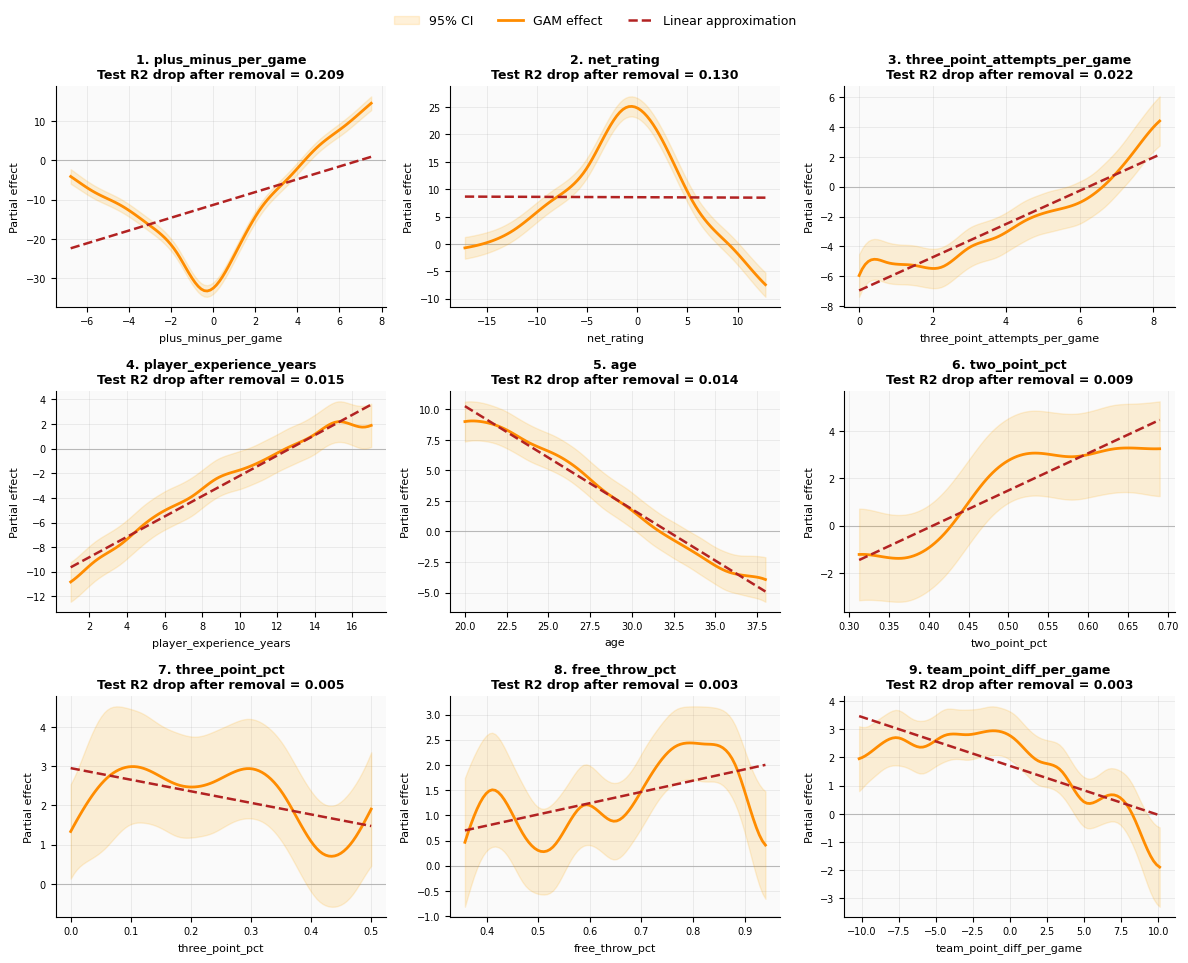

In [9]:
# ============================ TOP 9 GAM EFFECTS ============================
top_features=gam_results["variable"].head(9).tolist()
gam_data=X_tr[final_vars].copy()
baseline_values=gam_data.median().values.astype(float)

fig,axes=plt.subplots(3,3,figsize=(12,10))
fig.patch.set_facecolor("white")
axes=axes.reshape(-1)

for ax,feature in zip(axes,top_features):
    ax.set_facecolor("#fafafa")
    feature_index=final_vars.index(feature)
    x=np.linspace(gam_data[feature].quantile(0.01),gam_data[feature].quantile(0.99),100)
    XX=np.tile(baseline_values,(100,1))
    XX[:,feature_index]=x
    partial_effect,confidence_interval=gam_model.partial_dependence(term=feature_index,X=XX,width=0.95)
    linear_fit=np.polyval(np.polyfit(x,partial_effect,1),x)

    ax.axhline(0,color="#bbbbbb",linewidth=0.8,zorder=0)
    ax.fill_between(x,confidence_interval[:,0],confidence_interval[:,1],color="orange",alpha=0.15,label="95% CI")
    ax.plot(x,partial_effect,color="darkorange",linewidth=2,label="GAM effect")
    ax.plot(x,linear_fit,color="firebrick",linestyle="--",linewidth=1.8,label="Linear approximation")

    feature_result=gam_results.loc[gam_results["variable"]==feature]
    feature_rank=gam_results.index[gam_results["variable"]==feature][0]+1
    r2_drop_value=float(feature_result["R2 drop"].iloc[0])

    ax.set_title(f"{feature_rank}. {feature}\nTest R2 drop after removal = {r2_drop_value:.3f}",fontsize=9,fontweight="bold")
    ax.set_xlabel(feature,fontsize=8)
    ax.set_ylabel("Partial effect",fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.25,linewidth=0.6)
    ax.set_axisbelow(True)

    for spine in ("top","right"):
        ax.spines[spine].set_visible(False)

handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="upper center",bbox_to_anchor=(0.5,0.965),ncol=3,fontsize=9,frameon=False)
fig.tight_layout(rect=[0,0,1,0.93])
plt.show()

# Saving figure
regression_output_dir=Path.home()/"Desktop"/"NBA_Project"/"code"/"analysis"/"Regression"
regression_output_dir.mkdir(parents=True,exist_ok=True)

figure_path=regression_output_dir/"GAM Important Predictors.pdf"
fig.savefig(figure_path,dpi=300,bbox_inches="tight")
plt.show()


In [14]:
######################## Random Forest ###########################################################################

Best max_features: 1.0
Best CV MAE: 4.0343
SD across folds: 0.1652
SE across folds: 0.0739
selected_max_features = 1.0


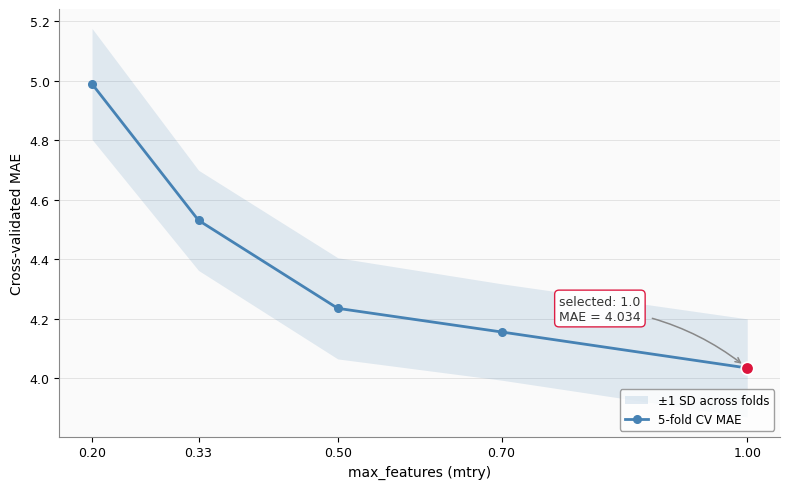

In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

training_groups=train["player_id"]
group_cv=GroupKFold(n_splits=5)
max_features_grid=[0.2,0.33,0.5,0.7,1.0]
cv_mae_scores=[]
fold_mae_scores=[]

for max_feature_value in max_features_grid:
    fold_scores_current=[]
    total_absolute_error=0
    total_samples=0
    for train_idx,valid_idx in group_cv.split(X_tr,groups=training_groups):
        X_fit,y_fit=X_tr.iloc[train_idx],y_tr.iloc[train_idx]
        X_valid,y_valid=X_tr.iloc[valid_idx],y_tr.iloc[valid_idx]
        rf_model=RandomForestRegressor(max_features=max_feature_value,random_state=42,n_jobs=-1).fit(X_fit,y_fit)
        predictions=rf_model.predict(X_valid)
        absolute_errors=np.abs(y_valid.to_numpy()-predictions)
        total_absolute_error+=absolute_errors.sum()
        total_samples+=len(absolute_errors)
        fold_scores_current.append(mean_absolute_error(y_valid,predictions))
    cv_mae_scores.append(total_absolute_error/total_samples)
    fold_mae_scores.append(fold_scores_current)

cv_mae_scores=np.array(cv_mae_scores)
fold_mae_scores=np.array(fold_mae_scores)
mean_cv_mae=cv_mae_scores
std_cv_mae=fold_mae_scores.std(axis=1)
se_cv_mae=std_cv_mae/np.sqrt(5)

best_index=int(np.argmin(mean_cv_mae))
selected_max_features=max_features_grid[best_index]
selected_best_mae=float(mean_cv_mae[best_index])

print(f"Best max_features: {selected_max_features}")
print(f"Best CV MAE: {selected_best_mae:.4f}")
print(f"SD across folds: {std_cv_mae[best_index]:.4f}")
print(f"SE across folds: {se_cv_mae[best_index]:.4f}")
print(f"selected_max_features = {selected_max_features}")

fig,ax=plt.subplots(figsize=(8,5))
fig.patch.set_facecolor("white")
ax.set_facecolor("#fafafa")

ax.fill_between(max_features_grid,mean_cv_mae-std_cv_mae,mean_cv_mae+std_cv_mae,color="steelblue",alpha=0.15,lw=0,label="±1 SD across folds")
ax.plot(max_features_grid,mean_cv_mae,"o-",color="steelblue",lw=2,ms=5.5,zorder=3,label="5-fold CV MAE")
ax.plot(selected_max_features,selected_best_mae,"o",color="crimson",ms=9,zorder=5,markeredgecolor="white",markeredgewidth=1.2)

ax.annotate(f"selected: {selected_max_features}\nMAE = {selected_best_mae:.3f}",
            xy=(selected_max_features,selected_best_mae),xytext=(selected_max_features-0.13,selected_best_mae+0.2),
            ha="right",va="center",fontsize=9,color="#333333",
            arrowprops=dict(arrowstyle="->",lw=1.1,color="#888888",connectionstyle="arc3,rad=-0.15",shrinkA=5,shrinkB=5),
            bbox=dict(boxstyle="round,pad=0.35",facecolor="white",edgecolor="crimson",linewidth=1.0,alpha=0.95))

ax.set_xticks(max_features_grid)
ax.tick_params(axis="both",labelsize=9)
ax.set_xlabel("max_features (mtry)",fontsize=10)
ax.set_ylabel("Cross-validated MAE",fontsize=10)
ax.grid(axis="y",color="#d9d9d9",linestyle="-",linewidth=0.7,alpha=0.7)
ax.set_axisbelow(True)

for s in ("top","right"):
    ax.spines[s].set_visible(False)

ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")
ax.legend(loc="lower right",fontsize=8.5,frameon=True,edgecolor="#888888",facecolor="white")
fig.tight_layout()

toPath=Path.home()/"Desktop"/"NBA_Project"/"code"/"analysis"/"Regression"
toPath.mkdir(parents=True,exist_ok=True)
fig.savefig(toPath/"MTRY Tuning.pdf",dpi=300,bbox_inches="tight")
plt.show()

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

#  FINAL RANDOM FOREST
# Training final Random Forest and predicting test data
rf_model=RandomForestRegressor(max_features=selected_max_features,
                         random_state=42,n_jobs=-1).fit(X_tr,y_tr)
pred_rf=rf_model.predict(X_te)

# CV RMSE and R2
gkf=GroupKFold(n_splits=5)
rmse_scores=[]
r2_scores=[]

for f_tr,f_va in gkf.split(X_tr,groups=train["player_id"]):
    m=RandomForestRegressor(max_features=selected_max_features,
                            random_state=42,n_jobs=-1).fit(X_tr.iloc[f_tr],y_tr.iloc[f_tr])
    
    pred=m.predict(X_tr.iloc[f_va])
    
    rmse_scores.append(np.sqrt(mean_squared_error(y_tr.iloc[f_va],pred)))
    r2_scores.append(r2_score(y_tr.iloc[f_va],pred))
#  RF SUMMARY 
# Summarizing CV and test results
rf_cv_mean= selected_best_mae
rf_cv_sd=std_cv_mae[best_index]
rf_cv_rmse_mean=np.mean(rmse_scores)
rf_cv_rmse_sd=np.std(rmse_scores)
rf_cv_r2_mean=np.mean(r2_scores)
rf_cv_r2_sd=np.std(r2_scores)

rf_summary=pd.DataFrame({
    "CV R2 mean":[rf_cv_r2_mean],
    "CV MAE mean":[rf_cv_mean],
    "CV RMSE mean":[rf_cv_rmse_mean],
    "Test R2":[r2_score(y_te,pred_rf)],
    "Test MAE":[mean_absolute_error(y_te,pred_rf)],
    "Test RMSE":[np.sqrt(mean_squared_error(y_te,pred_rf))]
},index=["Random Forest"]).rename_axis(None)

display(rf_summary.round(3))

#  PERMUTATION IMPORTANCE 
# Calculating permutation importance on the test data
perm=permutation_importance(rf_model,X_te,y_te,n_repeats=10,random_state=42,
                            n_jobs=-1,scoring="neg_mean_absolute_error")

importance_simple=pd.DataFrame(
    {"permutation importance":perm.importances_mean},
    index=final_vars
).sort_values("permutation importance",ascending=False)

display(importance_simple.round(3))

,CV R2 mean,CV MAE mean,CV RMSE mean,Test R2,Test MAE,Test RMSE
Random Forest,0.729,4.034,5.463,0.717,4.242,5.776


,permutation importance
plus_minus_per_game,6.227
net_rating,3.886
three_point_attempts_per_game,1.743
two_point_pct,0.455
team_point_diff_per_game,0.298
weight_kg,0.200
three_point_pct,0.128
player_experience_years,0.111
win_pct,0.098
age,0.070


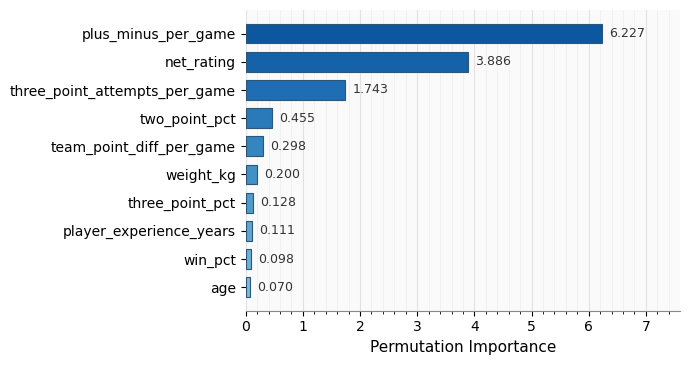

In [12]:
# ========================== RANDOM FOREST PERMUTATION IMPORTANCE ==========================
# Selecting the 10 most important predictors
top_k=10
plot_imp=importance_simple.head(top_k).iloc[::-1]

# Checking if standard deviations are available
has_std="std" in plot_imp.columns

fig,ax=plt.subplots(figsize=(7,3.75))
fig.patch.set_facecolor("white")
ax.set_facecolor("#fafafa")

# Creating colors for the bars
cmap=plt.cm.Blues
norm_vals=np.linspace(0.45,0.85,len(plot_imp))
colors=[cmap(v) for v in norm_vals]

bars=ax.barh(
    plot_imp.index,plot_imp["permutation importance"],
    xerr=plot_imp["std"] if has_std else None,
    color=colors,edgecolor="#2c5577",linewidth=0.8,height=0.7,
    error_kw=dict(ecolor="#555555",elinewidth=1,capsize=3,alpha=0.8) if has_std else {},
)

# Adding importance values to the bars
max_val=plot_imp["permutation importance"].max()
offset=max_val*0.02

for b,v in zip(bars,plot_imp["permutation importance"]):
    ax.text(b.get_width()+offset,b.get_y()+b.get_height()/2,
            f"{v:.3f}",va="center",ha="left",fontsize=9,color="#333333")

ax.set_xlabel("Permutation Importance",fontsize=11)
ax.set_ylabel("")
ax.tick_params(axis="y",labelsize=10)
ax.tick_params(axis="x",labelsize=10)
ax.set_axisbelow(True)
ax.set_xlim(0,max_val*1.22)

# Adding grid lines
ax.grid(which="major",axis="x",color="#d9d9d9",linestyle="-",linewidth=0.8,alpha=0.7)
ax.xaxis.set_minor_locator(plt.matplotlib.ticker.AutoMinorLocator())
ax.grid(which="minor",axis="x",color="#eeeeee",linestyle="-",linewidth=0.6,alpha=0.9)

for s in ("top","right","left"):
    ax.spines[s].set_visible(False)

ax.spines["bottom"].set_color("#888888")

fig.tight_layout()

# Saving figure
toPath=Path.home()/"Desktop"/"NBA_Project (1)"/"NBA_Project"/"code"/"analysis"/"Regression"
toPath.mkdir(parents=True,exist_ok=True)

save_path=toPath/"Random Forest Permutation Importance.pdf"
fig.savefig(save_path,dpi=300,bbox_inches="tight")
plt.show()